# 1016 — spot test 結果判讀

10/12 點盤、10/16 看結果。7 株菌的 double-layer lawn（200 µL 菌液 + 3 mL soft agar），每盤分 5 區，每區點 7 µL：

| 區 | 內容 | 角色 |
|---|---|---|
| `Φ8` | phage 原液 | positive control |
| `PBS` | 1× PBS | negative control |
| `e1` | 純化 e1，1:10 | |
| `e40` | e40 crude lysate，1:10 | |
| `e281` | e281 crude lysate，1:10 | |

- 照片：[`../data/assays/1016_spot_test/`](../data/assays/1016_spot_test/)，`_F` = 正面（寫菌株名），`_B` = 背面（畫線、寫區名）
- 背面的字從背面拍是鏡像：`SBd` = PBS、`1e` = e1、`04e` = e40、`182e` = e281
- 這裡把背面照片**左右翻轉**，等於從正面看，再依「標籤落在哪一區」指派每一滴

**待確認（CONFIRM）**
- **lawn 有長起來嗎？** 拿盤子對光看，滴以外的 soft agar 跟一般 LB 盤比是不是混濁的。照片每滴只有 ~60 px，判斷不了；這題決定下面第 5 節要怎麼讀。
- Φ8 那區大多有兩個圈（一大一小），那區是不是點了兩滴？哪一個才是 Φ8？這裡取的是外圈；如果內圈才是，Φ8 那欄量錯滴了。
- `9-1-1`：Φ8 那滴長滿菌落、最暗的是 e40、e281 只有一個很小的淡圈，這跟「整盤錯一區」的樣子一樣。標籤檢查過了，但請看實體盤確認。
- `1015_spot_test_dilution.ipynb` 寫的是「明天（10/16）spot test」用的等濃度稀釋表，但這批盤 10/12 就點了、用的是 1:10，所以**沒用那張表**，各管蛋白量不同、沒量過。10/16 另外有點一批嗎？
- `e1` 寫「純化」，但 notebook 裡只有 10/01 純化 CDS10 / e40、10/10 e281 純化失敗的紀錄，沒有 e1 純化成功的紀錄。
- 1015 的樣品名有 `e1+`、`e40-`（± IPTG？），這次點的是哪一管？
- 1:10 是用什麼稀釋的（PBS / lysis buffer / elution buffer）？PBS 有滅菌嗎？
- R1 = 10/10 送 WGS（SBYK6W）的那兩株嗎？

In [1]:
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy import ndimage
import matplotlib.pyplot as plt

IMG = '../data/assays/1016_spot_test'
OUT = 'output/1016_spot_test_result'
CROP = (230, 360, 750, 880)    # 翻轉後的背面照片裡，平板的範圍 (px)
Z = 900 / 520                  # 下面座標是在放大到 900 px 的圖上量的
COLS = ['phi8', 'PBS', 'e1', 'e40', 'e281']

## 1. 每一滴的位置

座標 = 翻轉 + 裁切 + 放大到 900 px 後的圖上，每滴的圓心。每個標籤都確認過落在單一區內、五個標籤各佔一區。
`Φ8` 區通常有兩個圈（一大一小），取的是靠外圈那個；`9-1-1` 的 `e281` 只看到一個很小的淡圈，位置最不確定。

In [2]:
spots = {
    '9-2-1':    {'phi8': (445, 700), 'PBS': (645, 505), 'e1': (230, 500), 'e40': (340, 280), 'e281': (560, 315)},
    '9-2-1_R1': {'phi8': (540, 690), 'PBS': (655, 480), 'e1': (275, 615), 'e40': (255, 340), 'e281': (535, 315)},
    '9-6-2':    {'phi8': (385, 680), 'PBS': (245, 560), 'e1': (310, 320), 'e40': (555, 340), 'e281': (605, 580)},
    '9-6-2_R1': {'phi8': (370, 670), 'PBS': (650, 510), 'e1': (210, 450), 'e40': (390, 210), 'e281': (605, 295)},
    '8-10-2':   {'phi8': (365, 730), 'PBS': (225, 545), 'e1': (335, 320), 'e40': (590, 350), 'e281': (605, 640)},
    '9-1-1':    {'phi8': (350, 710), 'PBS': (565, 665), 'e1': (265, 455), 'e40': (440, 245), 'e281': (725, 505)},
    '10-10-2':  {'phi8': (285, 680), 'PBS': (240, 460), 'e1': (430, 285), 'e40': (630, 430), 'e281': (570, 660)},
}

def plate(name, mode='RGB'):
    return ImageOps.mirror(Image.open(f'{IMG}/{name}_B.jpeg').convert(mode)).crop(CROP)

## 2. 矩陣圖

列 = 菌株（親代 / R1 成對放），欄 = 5 種處理；最左是整盤（看得到手寫標籤，可以自己核對指派）。原始顏色，沒調色。

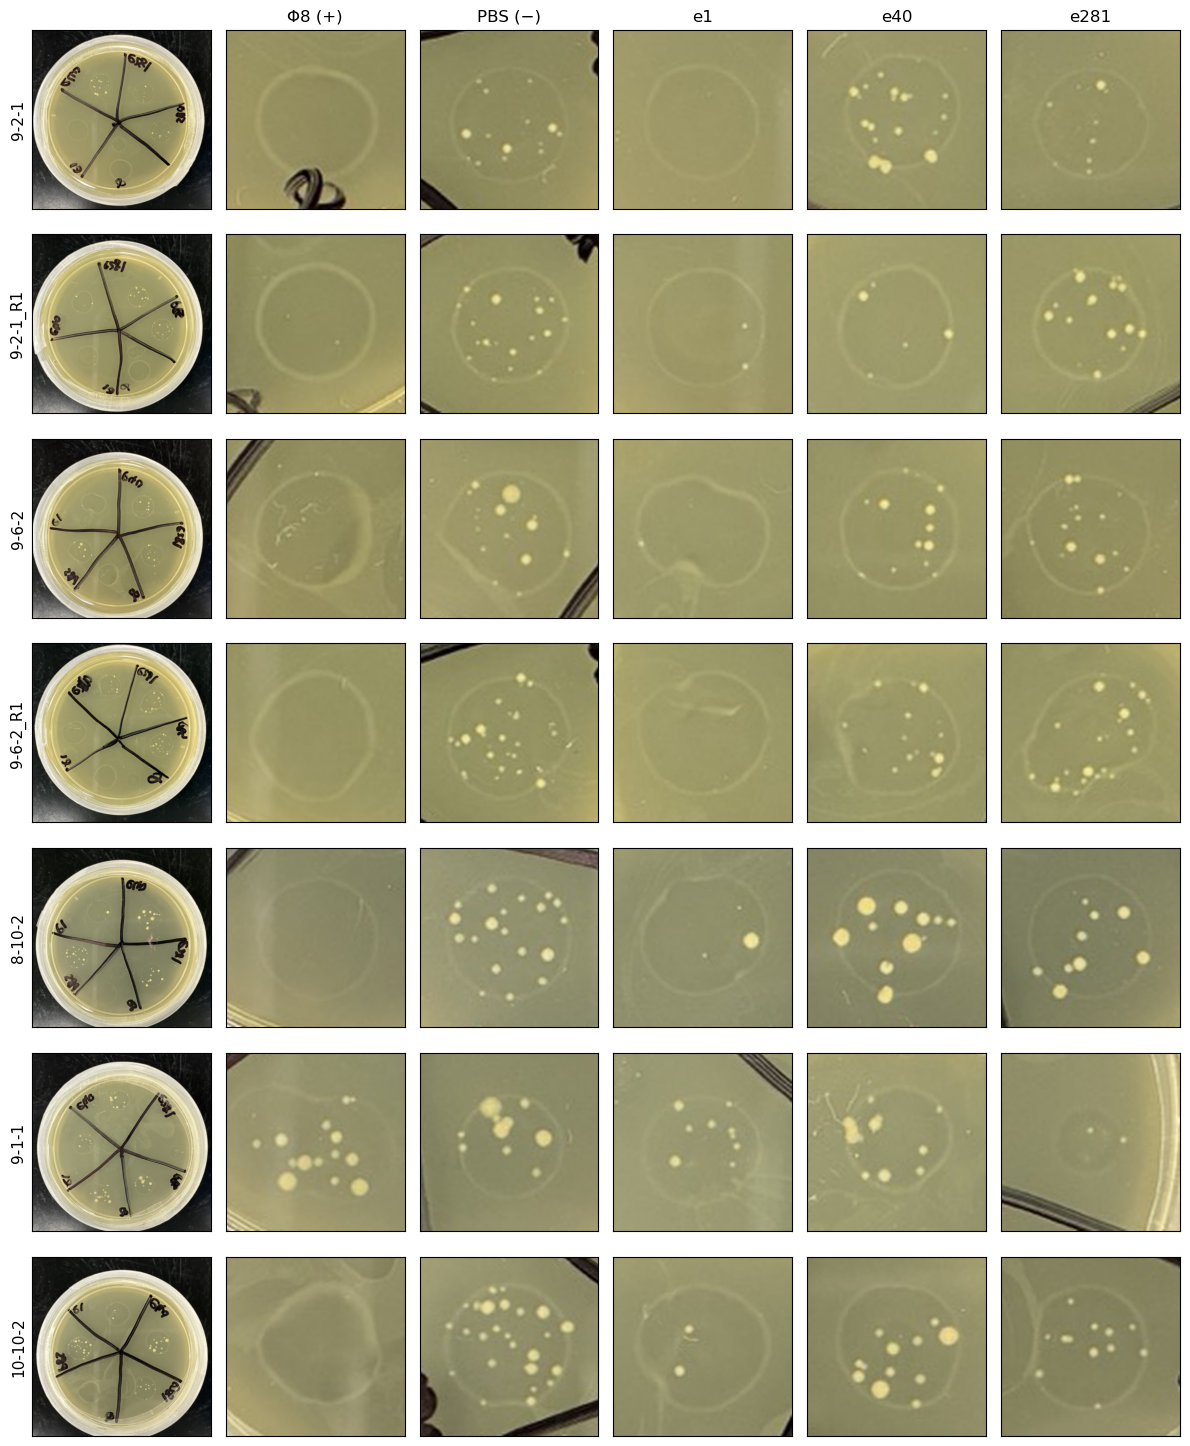

In [3]:
fig, ax = plt.subplots(len(spots), 6, figsize=(12, 2.1 * len(spots)))
for i, (p, d) in enumerate(spots.items()):
    im = plate(p)
    ax[i, 0].imshow(im)
    ax[i, 0].set_ylabel(p, fontsize=11)
    for j, k in enumerate(COLS):
        x, y = d[k][0] / Z, d[k][1] / Z
        ax[i, j + 1].imshow(im.crop((x - 48, y - 48, x + 48, y + 48)).resize((300, 300), Image.LANCZOS))
        if i == 0:
            ax[i, j + 1].set_title({'phi8': 'Φ8 (+)', 'PBS': 'PBS (−)'}.get(k, k))
    for a in ax[i]:
        a.set_xticks([]); a.set_yticks([])
fig.tight_layout()
fig.savefig(f'{OUT}/spot_matrix.png', dpi=200)
plt.show()

## 3. 每滴裡的菌落數

半徑 30 px 的圓內，比圓內中位數亮 22 以上、≥ 3 px 的連通塊算一顆。黏在一起的會算成一顆，所以是**下限**；`9-6-2` Φ8 的 3 顆是圈邊的反光，不是菌落。

In [4]:
rows = []
for p, d in spots.items():
    g = np.asarray(plate(p, 'L'), float)
    yy, xx = np.mgrid[:g.shape[0], :g.shape[1]]
    for k in COLS:
        x, y = d[k][0] / Z, d[k][1] / Z
        r = np.hypot(xx - x, yy - y)
        disk = r < 30
        lab, n = ndimage.label((g > np.median(g[disk]) + 22) & disk)
        sizes = ndimage.sum(np.ones_like(g), lab, range(1, n + 1))
        clear = np.median(g[r < 20]) - np.median(g[(r > 35) & (r < 46)])   # 負 = 比外面暗 = 比較透
        rows.append(dict(strain=p, spot=k, colonies=int((sizes >= 3).sum()), inside_minus_lawn=clear))
res = pd.DataFrame(rows)
counts = res.pivot(index='strain', columns='spot', values='colonies').loc[list(spots), COLS]
counts

spot,phi8,PBS,e1,e40,e281
strain,,,,,
9-2-1,0,11,0,13,5
9-2-1_R1,0,14,1,4,11
9-6-2,3,8,1,8,9
9-6-2_R1,0,17,1,11,13
8-10-2,0,15,3,10,7
9-1-1,11,7,8,9,2
10-10-2,1,17,4,10,9


## 4. 有沒有透（lysis）

圓內亮度 − 圓外 lawn 亮度。背景是黑桌面，越透越暗 → 負值。差異只有幾個灰階，**很弱**，只當輔助；肉眼在矩陣圖上看不到任何一滴有明顯透明區。

In [5]:
bright = res.pivot(index='strain', columns='spot', values='inside_minus_lawn').loc[list(spots), COLS].round(1)
res.to_csv(f'{OUT}/spot_calls.tsv', sep='\t', index=False)
print('每盤最暗（最透）的那滴:', bright.idxmin(axis=1).to_dict())
bright

每盤最暗（最透）的那滴: {'9-2-1': 'phi8', '9-2-1_R1': 'phi8', '9-6-2': 'phi8', '9-6-2_R1': 'phi8', '8-10-2': 'phi8', '9-1-1': 'e40', '10-10-2': 'phi8'}


spot,phi8,PBS,e1,e40,e281
strain,,,,,
9-2-1,-4.0,0.0,-2.0,1.0,-1.0
9-2-1_R1,-3.0,1.0,-1.0,0.0,-2.0
9-6-2,-4.0,-2.0,-2.0,-1.0,-1.0
9-6-2_R1,-4.0,0.0,0.0,-2.0,-1.0
8-10-2,-3.0,0.0,-1.0,3.0,-2.0
9-1-1,-3.0,-2.0,-3.0,-4.0,-1.0
10-10-2,-9.0,2.0,-1.0,-3.0,-1.0


## 5. 判讀

**看得到的**
1. **照片上看不到任何一滴有透明區**，包括 Φ8 點在它自己的宿主 9-2-1、9-6-2 上：要嘛 Φ8 沒有裂解，要嘛 **lawn 根本沒長成**（菌落只出現在滴裡、從不在滴外，7 株長得都一樣，也符合沒有 lawn）。亮度上 Φ8 是 6/7 盤最暗的一滴，但只差幾個灰階。
2. **菌落出現在 PBS、e40、e281 這三種滴裡，每一盤都有**（約 4–17 顆；`9-1-1` 的 e281 位置不確定，不算），菌落長相一樣（奶黃色、圓、大小不一）。
3. **Φ8 那滴乾淨**（6/7 盤 0 顆），**e1 那滴幾乎乾淨**（0–4 顆）。例外是 `9-1-1`：Φ8 和 e1 那滴也都長滿菌落（**未確認**，可能是整盤指派錯一區，見 CONFIRM）。
4. **R1 和親代看起來一樣**：Φ8 在 9-2-1 vs 9-2-1 R1、9-6-2 vs 9-6-2 R1 都是乾淨的圈、沒有透明區。

**不能下的結論**
- **PBS（negative control）也長菌落**，所以這些菌落**不是**「被裂解後存活的抗性菌」，也不能當作 e40 / e281 有沒有活性的證據。比較像是液體本身帶進來的菌（PBS 沒滅菌、或用同一管 PBS 稀釋），但這要看 1:10 用什麼稀釋才知道。
- Φ8 那滴乾淨可能是 phage 殺掉了帶進來的菌，也可能只是 phage 原液本來就是過濾過的乾淨液體，**單看這盤分不出來**。
- **positive control 沒有出現明顯透明區**（不管原因是 Φ8 還是 lawn），所以這盤不能說 e1 / e40 / e281 有沒有活性，**也不能判斷 R1 是不是對 Φ8 有抗性**（親代本身就沒看到裂解，比不出差別）。

**UNDONE**
- 確認 lawn：菌液 OD / 活性、soft agar 溫度，點一盤不點東西的 lawn 對照
- 無菌檢查：PBS 原液、e1、e40、e281 各 7 µL 點在沒有 lawn 的 LB 盤上
- 蛋白先 0.22 µm 過濾再點
- Φ8 做 10 倍稀釋系列（10⁰–10⁻⁶），確認在親代上有透明區 / plaque，再拿來比 R1
- 用 1015 的等濃度表重點一次，三種蛋白用同一種 buffer，並點一滴只有 buffer 的 control

## 6. 論文 / wiki 用的圖

A = 每滴的裁切（原始顏色），B = 每滴裡的菌落數，一點 = 一株菌，橫線 = 中位數。`9-1-1` 畫空心（區的指派還沒確認）。
caption 在 `output/1016_spot_test_result/figure_caption.md`。

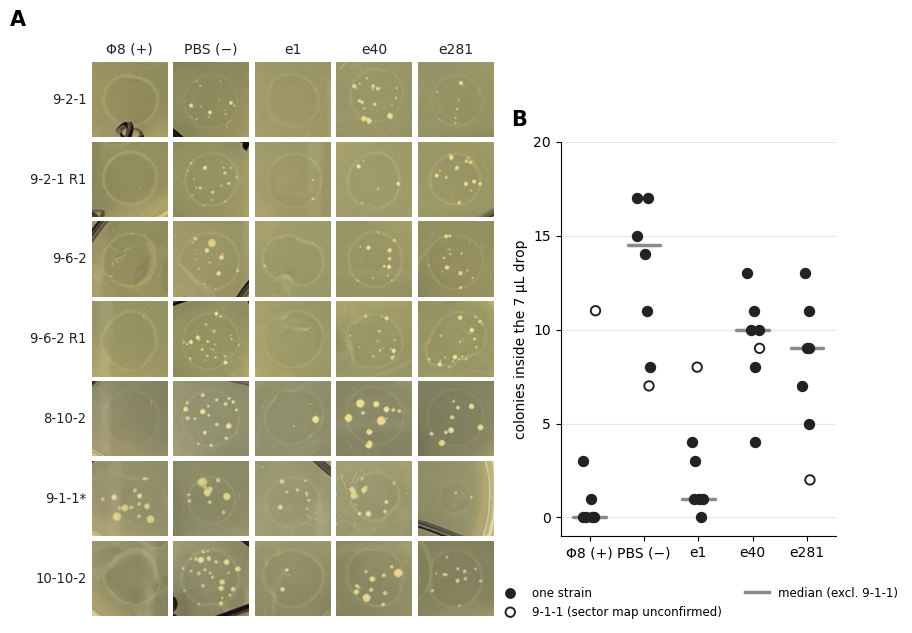

median colonies (excl. 9-1-1): {'phi8': 0.0, 'PBS': 14.5, 'e1': 1.0, 'e40': 10.0, 'e281': 9.0}


In [6]:
from matplotlib.gridspec import GridSpec

NAMES = {'phi8': 'Φ8 (+)', 'PBS': 'PBS (−)', 'e1': 'e1', 'e40': 'e40', 'e281': 'e281'}
ROWS = {'9-2-1': '9-2-1', '9-2-1_R1': '9-2-1 R1', '9-6-2': '9-6-2', '9-6-2_R1': '9-6-2 R1',
        '8-10-2': '8-10-2', '9-1-1': '9-1-1*', '10-10-2': '10-10-2'}
INK, MUTED = '#222222', '#8a8a8a'

fig = plt.figure(figsize=(9.6, 7.2))
gs = GridSpec(len(spots), 7, figure=fig, width_ratios=[1] * 5 + [0.75, 3.6], wspace=0.05, hspace=0.06)
for i, (p, d) in enumerate(spots.items()):
    im = plate(p)
    for j, k in enumerate(COLS):
        a = fig.add_subplot(gs[i, j])
        x, y = d[k][0] / Z, d[k][1] / Z
        a.imshow(im.crop((x - 44, y - 44, x + 44, y + 44)).resize((240, 240), Image.LANCZOS))
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)
        if i == 0:
            a.set_title(NAMES[k], fontsize=10, color=INK)
        if j == 0:
            a.set_ylabel(ROWS[p], fontsize=9.5, color=INK, rotation=0, ha='right', va='center')
fig.text(0.04, 0.93, 'A', fontsize=15, weight='bold')

b = fig.add_subplot(gs[1:6, 6])
rng = np.random.default_rng(0)
for j, k in enumerate(COLS):
    sub = res[res.spot == k]
    ok = sub[sub.strain != '9-1-1']
    jit = rng.uniform(-0.13, 0.13, len(sub))
    for (_, r), dx in zip(sub.iterrows(), jit):
        hollow = r.strain == '9-1-1'
        b.scatter(j + dx, r.colonies, s=46, zorder=3, linewidths=1.4,
                  facecolor='none' if hollow else INK, edgecolor=INK)
    m = ok.colonies.median()
    b.plot([j - 0.3, j + 0.3], [m, m], color=MUTED, lw=2.5, solid_capstyle='round', zorder=2)
b.set_xticks(range(len(COLS)), [NAMES[k] for k in COLS], fontsize=10)
b.set_ylabel('colonies inside the 7 µL drop', fontsize=10)
b.set_ylim(-1, 20)
b.set_yticks(range(0, 21, 5))
b.grid(axis='y', color='#e6e6e6', lw=0.8); b.set_axisbelow(True)
for s in ['top', 'right']:
    b.spines[s].set_visible(False)
b.text(-0.18, 1.04, 'B', transform=b.transAxes, fontsize=15, weight='bold')
b.scatter([], [], s=46, facecolor=INK, edgecolor=INK, label='one strain')
b.scatter([], [], s=46, facecolor='none', edgecolor=INK, lw=1.4, label='9-1-1 (sector map unconfirmed)')
b.plot([], [], color=MUTED, lw=2.5, label='median (excl. 9-1-1)')
b.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.savefig(f'{OUT}/fig_spot_test.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{OUT}/fig_spot_test.pdf', bbox_inches='tight')
plt.show()
med = res[res.strain != '9-1-1'].groupby('spot').colonies.median().loc[COLS]
print('median colonies (excl. 9-1-1):', med.to_dict())